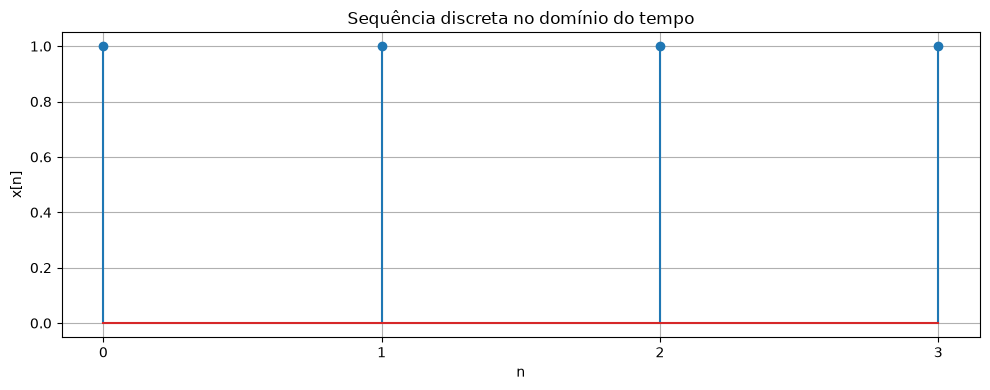

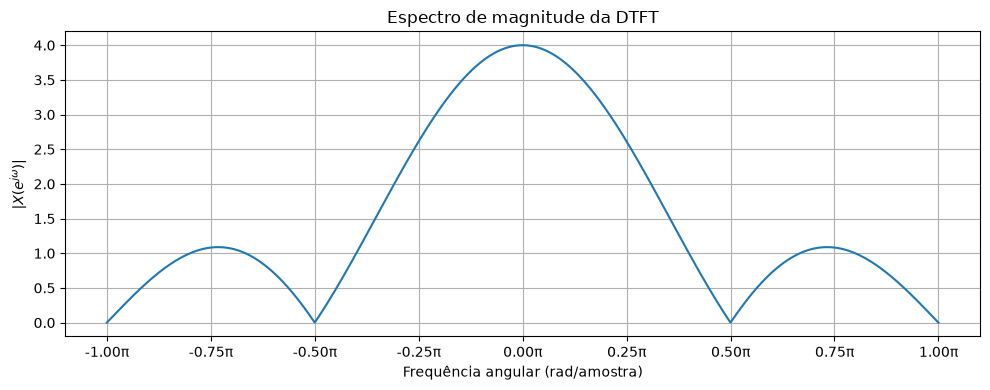

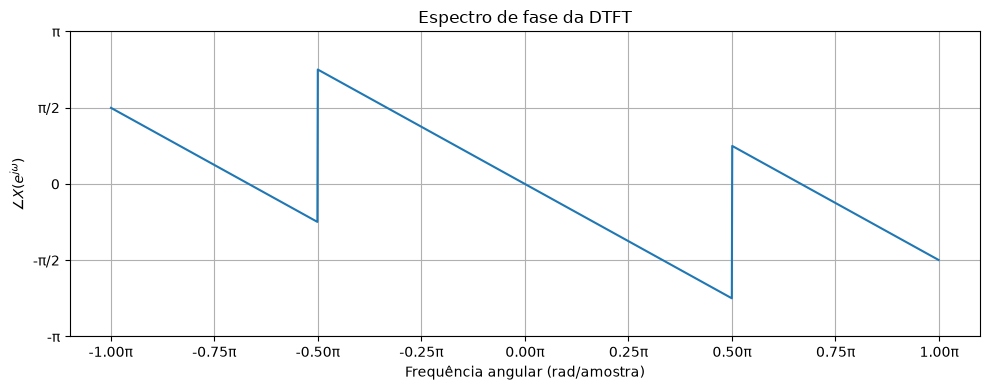

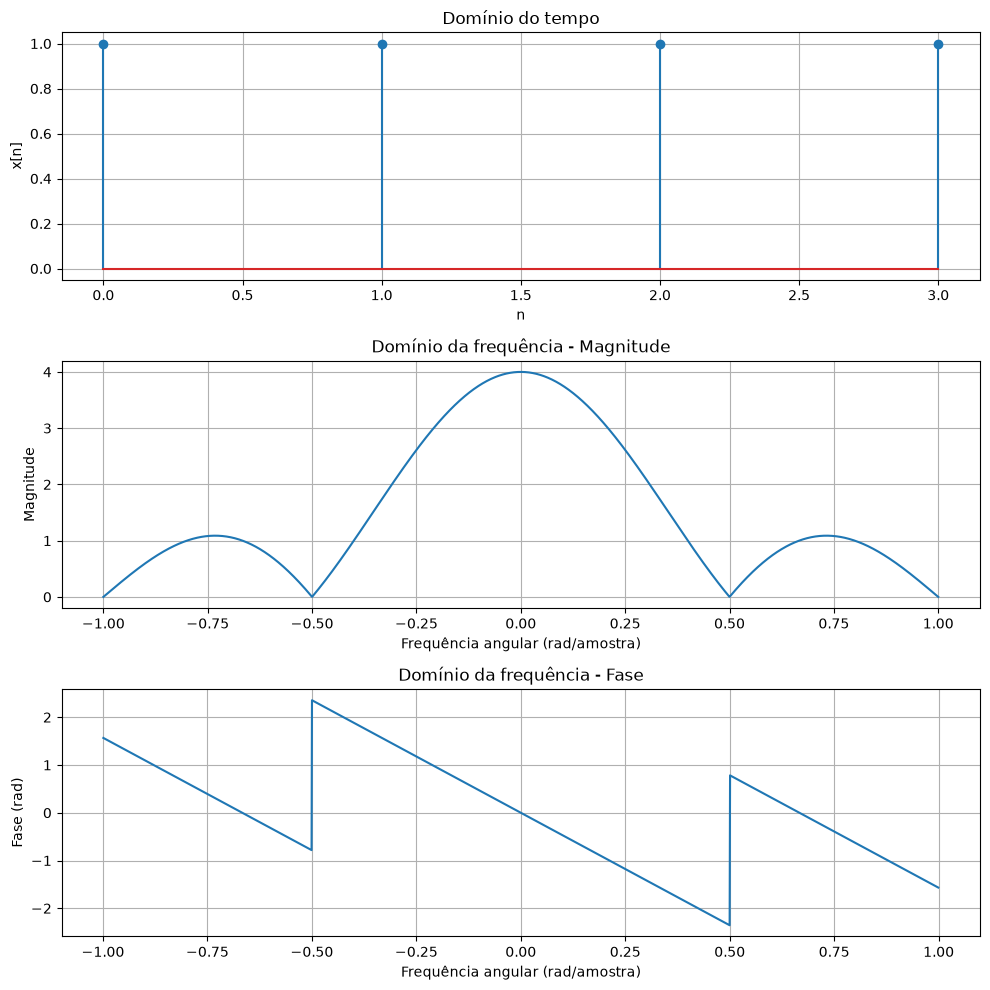

Análise da DTFT
--------------------------------
Número de amostras: 4
Soma das amostras: 4.0
Magnitude em ω = 0: 3.9999938253267224
Magnitude máxima: 3.9999938253267224
Magnitude mínima: 2.449293598294706e-16

Simulação concluída!


In [1]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURAÇÕES GERAIS
# ============================================================

# Sequência discreta
n = np.arange(0, 4)
x = np.ones(len(n))

# Eixo de frequência angular
omega = np.linspace(-np.pi, np.pi, 2000)


# ============================================================
# 1. CÁLCULO DA DTFT
# ============================================================

def calcular_dtft(x, n, omega):
    """
    Calcula numericamente a DTFT de uma sequência discreta.

    X(e^jw) = sum(x[n] * exp(-j*w*n))
    """

    X = np.zeros(len(omega), dtype=complex)

    for i, w in enumerate(omega):
        X[i] = np.sum(x * np.exp(-1j * w * n))

    return X


X = calcular_dtft(x, n, omega)


# ============================================================
# 2. ESPECTRO DE MAGNITUDE E FASE
# ============================================================

magnitude = np.abs(X)
fase = np.angle(X)

# Evita exibir valores de fase em regiões de magnitude
# praticamente nula, onde a fase não é bem definida.
fase[magnitude < 1e-6] = np.nan


# ============================================================
# 3. REPRESENTAÇÃO NO DOMÍNIO DO TEMPO
# ============================================================

plt.figure(figsize=(10, 4))

plt.stem(n, x)

plt.title("Sequência discreta no domínio do tempo")
plt.xlabel("n")
plt.ylabel("x[n]")

plt.xticks(n)
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 4. ESPECTRO DE MAGNITUDE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(omega / np.pi, magnitude)

plt.title("Espectro de magnitude da DTFT")
plt.xlabel("Frequência angular (rad/amostra)")
plt.ylabel(r"$|X(e^{j\omega})|$")

plt.xticks(
    np.arange(-1, 1.1, 0.25),
    [f"{v:.2f}π" for v in np.arange(-1, 1.1, 0.25)]
)

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 5. ESPECTRO DE FASE
# ============================================================

plt.figure(figsize=(10, 4))

plt.plot(omega / np.pi, fase)

plt.title("Espectro de fase da DTFT")
plt.xlabel("Frequência angular (rad/amostra)")
plt.ylabel(r"$\angle X(e^{j\omega})$")

plt.xticks(
    np.arange(-1, 1.1, 0.25),
    [f"{v:.2f}π" for v in np.arange(-1, 1.1, 0.25)]
)

plt.yticks(
    [-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
    ["-π", "-π/2", "0", "π/2", "π"]
)

plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 6. COMPARAÇÃO ENTRE TEMPO E FREQUÊNCIA
# ============================================================

fig, ax = plt.subplots(3, 1, figsize=(10, 10))

# Domínio do tempo
ax[0].stem(n, x)
ax[0].set_title("Domínio do tempo")
ax[0].set_xlabel("n")
ax[0].set_ylabel("x[n]")
ax[0].grid(True)

# Espectro de magnitude
ax[1].plot(omega / np.pi, magnitude)
ax[1].set_title("Domínio da frequência - Magnitude")
ax[1].set_xlabel("Frequência angular (rad/amostra)")
ax[1].set_ylabel("Magnitude")
ax[1].grid(True)

# Espectro de fase
ax[2].plot(omega / np.pi, fase)
ax[2].set_title("Domínio da frequência - Fase")
ax[2].set_xlabel("Frequência angular (rad/amostra)")
ax[2].set_ylabel("Fase (rad)")
ax[2].grid(True)

plt.tight_layout()
plt.show()


# ============================================================
# 7. VERIFICAÇÃO DE ALGUMAS PROPRIEDADES
# ============================================================

print("Análise da DTFT")
print("--------------------------------")

print("Número de amostras:", len(x))
print("Soma das amostras:", np.sum(x))

# Valor da DTFT em frequência zero
indice_zero = np.argmin(np.abs(omega))

print("Magnitude em ω = 0:",
      magnitude[indice_zero])

print("Magnitude máxima:",
      np.max(magnitude))

print("Magnitude mínima:",
      np.min(magnitude))

print("\nSimulação concluída!")
